# Exploring HANCOCK with KaleCancer

**Research questions on real head and neck cancer data**

The walkthrough used synthetic data. Here we use **HANCOCK**, a public multimodal cohort of 763 head and neck cancer patients, all treated with surgery at one German hospital. For each patient we have:

| Data | What it holds |
| --- | --- |
| Clinical table | age, sex, smoking, metastasis at diagnosis, follow-up and outcomes |
| Pathology report | tumour site, pT and pN stage, grade, HPV (p16) status, invasion, resection status |
| Blood tests | 33 routine tests taken just before treatment |
| Slides | features of the primary-tumour H&E slide, from the UNI pathology foundation model |

**How this works.** Section 1 trains one model, step by step. Each question after it is answered by changing a line or two. Pick the ones that interest you, in any order.

| Level | How much code you'll touch |
| --- | --- |
| 🟢 | change a value and rerun |
| 🟡 | edit a list or one line of code |
| 🔴 | write a little code of your own |

Every cell runs as it is. Lines marked `✏️` are the ones to change, with ideas next to them, and each question has hidden hints. Every model you train is added to a **results table** at the end, ready for the closing discussion.

These results are real, so some ideas won't help. A clear "this did not help", with a confidence interval, is a result too.

<details><summary>About the data</summary>

HANCOCK is released under [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) at [hancock.research.fau.eu](https://hancock.research.fau.eu). Please cite: Dörrich, M., Balk, M., Heusinger, T. et al. *A multimodal dataset for precision oncology in head and neck cancer.* Nat Commun 16, 7163 (2025). [doi:10.1038/s41467-025-62386-6](https://doi.org/10.1038/s41467-025-62386-6)

For this session we use a reduced copy, about 190 MB instead of hundreds of GB, so it downloads in seconds and trains on a laptop CPU. It keeps selected clinical and pathology columns, the blood tests closest to treatment, and a random 128 slide patches per patient. `prepare_hancock_bundle.py` builds it from the original download. Not for clinical use.
</details>

In [1]:
import logging
import warnings
import pandas as pd
import torch
from IPython.display import display

warnings.filterwarnings('ignore', message='IProgress not found')
logging.getLogger('lightning').setLevel(logging.ERROR)

## 0 Load the data

`fetch_hancock` downloads the data the first time, checks it, and reuses it after that. Each file is an ordinary CSV indexed by patient id, as your own data might be.

In [2]:
from hancock_data import fetch_hancock

folder = fetch_hancock('../../../data')

ids = {'patient_id': str}  # Ids are zero-padded, like '001', so read them as text
clinical_table = pd.read_csv(folder / 'clinical.csv', index_col=0, dtype=ids)
pathology_table = pd.read_csv(folder / 'pathology.csv', index_col=0, dtype=ids)
blood_table = pd.read_csv(folder / 'blood.csv', index_col=0, dtype=ids)

display(clinical_table.head(3))

,age_at_initial_diagnosis,sex,smoking_status,primarily_metastasis,days_to_last_information,survival_status,recurrence,days_to_recurrence
patient_id,,,,,,,,
001,65,male,former,no,2258,living,no,NaN
002,62,male,smoker,yes,1753,living,yes,357.0
003,60,male,non-smoker,no,851,living,no,NaN


## 1 The baseline: clinical table + slides

This is the walkthrough's recipe on real data. The outcome is **overall survival**: `days_to_last_information` is each patient's follow-up, and `survival_status` says whether they died then or were still alive when follow-up ended (censored).

`official_split` applies the train/test split published with HANCOCK, so results can be compared across papers.

In [3]:
from kalecancer.loaddata import Tabular, PatchFeatures, TimeToEvent, MultimodalDataset
from hancock_data import official_split

BASELINE_COLUMNS = ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primarily_metastasis']
clinical = clinical_table[BASELINE_COLUMNS]
slides = PatchFeatures.from_glob(str(folder / 'slides' / '*.h5'), id_pattern=r'(\d{3})\.h5')

overall_survival = TimeToEvent(
    time=clinical_table['days_to_last_information'],
    event=clinical_table['survival_status'] == 'deceased'
)

dataset = MultimodalDataset(
    modalities={'clinical': Tabular(clinical), 'slides': slides},
    target=overall_survival,
    required_modalities=[]
)
train, test = official_split(dataset, 'in')
display(dataset.summary())

,count
available: clinical,763
available: slides,701
available: target,763
included,763
included with clinical,763
included with slides,701
events,213


Each modality gets an encoder, `MaskedMean` combines them (and copes with the 62 patients who have no slide), and a Cox head predicts risk. `table_transform` scales the numeric columns and numbers the text ones.

In [4]:
from functools import partial
from kalecancer.model import ABMIL, MLP, IntermediateFusion, MaskedMean, CoxHead
from kalecancer.pipeline import Pipeline
from kalecancer.evaluate import HarrellC
from hancock_data import table_transform

torch.manual_seed(0)
model = IntermediateFusion(
    encoders={'clinical': [MLP(in_dim=4, hidden_dims=[64], out_dim=64, dropout=0.25)],
              'slides': [ABMIL(in_dim=1024, hidden_dim=64, attention_dim=32, dropout=0.25)]},
    fusion=MaskedMean(),
    head=CoxHead(in_dim=64, ties='efron')
)

pipeline = Pipeline(
    model=model,
    transforms={'clinical': table_transform(clinical)},
    optimizer=partial(torch.optim.AdamW, lr=1e-3, weight_decay=1e-2),
    batch_size=64, drop_last=False, max_epochs=10,
    validation=None, early_stopping=None,  # A fixed 10 epochs, chosen by cross-validation
    accelerator='cpu', precision='32-true', random_state=0
)
pipeline.fit(train)
pipeline.evaluate(test, {'harrell_c': HarrellC()})

harrell_c    0.662024
Name: score, dtype: float64

A C-index of 0.5 is chance and 1 is perfect ranking. For overall survival, 0.65 to 0.75 is typical of clinical models.

From here on, `experiment` repeats exactly these steps for whatever modalities, outcome and split you give it, and adds a 95% confidence interval. Its `modalities` are just like `MultimodalDataset`'s, except that tables can be plain DataFrames: each table gets an `MLP`, and the slides get `ABMIL`. `compare` gives the interval of the *difference* between two models on the same patients. Both are in `hancock_data.py` if you want to look.

**Do the slides help?**

In [5]:
from hancock_data import experiment, compare

clinical_only = experiment('Clinical', {'clinical': clinical})
baseline = experiment('Clinical + slides', {'clinical': clinical, 'slides': slides})
compare(baseline, clinical_only)

Clinical (in split): C-index 0.651 (95% CI 0.57 to 0.73)


Clinical + slides (in split): C-index 0.662 (95% CI 0.58 to 0.74)


Gain: +0.011 (95% CI -0.09 to +0.11): no clear difference


Look at the interval, not only the point estimate. If it spans zero, this test set of about 150 patients can't tell the two models apart. The KaleCancer HANCOCK example, with a larger tabular encoder and every patch of every slide, found no clear gain from the slides either. The questions below ask where extra data *does* help.

---
## Question 1 🟢 Does the model work at a different tumour site?

A model trained on one population often fails on another. The `Oropharynx` split trains on larynx, oral cavity and hypopharynx tumours, then tests on oropharynx tumours, which are often HPV-driven and behave differently.

**Your task:** change `SPLIT` and rerun. How much does the C-index drop compared with the random `in` split?

In [6]:
SPLIT = 'Oropharynx'  # ✏️ try 'in', 'out' or 'Oropharynx'

site_clinical = experiment('Clinical', {'clinical': clinical}, split=SPLIT)
site_fused = experiment('Clinical + slides', {'clinical': clinical, 'slides': slides}, split=SPLIT)
compare(site_fused, site_clinical)

Clinical (Oropharynx split): C-index 0.583 (95% CI 0.52 to 0.64)


Clinical + slides (Oropharynx split): C-index 0.614 (95% CI 0.55 to 0.68)


Gain: +0.031 (95% CI -0.05 to +0.11): no clear difference


<details><summary>Hints</summary>

Compare each model with its `in` result in the results table at the end. Training without any oropharynx patients tests whether the model has learned something general. The `out` split picks test patients who differ from the training patients, a second robustness check. Check whether the intervals overlap before concluding anything.
</details>

---
## Question 2 🟢 Who is at high risk?

Survival models are usually reported by splitting patients into risk groups and drawing their Kaplan-Meier curves. `kaplan_meier` does the grouping and `LogRank` tests whether the curves differ.

**Your task:** change `N_GROUPS` to 3 or 4. Do the extra groups separate, or do the middle curves overlap?

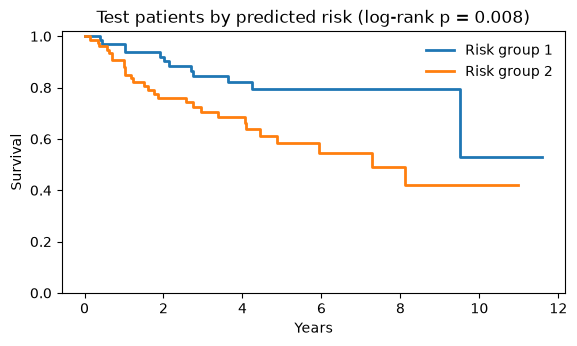

In [7]:
import matplotlib.pyplot as plt
from scipy.stats import chi2
from kalecancer.evaluate import LogRank, kaplan_meier

N_GROUPS = 2  # ✏️ try different sized groups

predictions, truth = baseline['predictions'], baseline['truth']
labels = [f'Risk group {group + 1}' for group in range(N_GROUPS)]  # Group 1 has the lowest predicted risk
curves = kaplan_meier(predictions, truth, n_groups=N_GROUPS, labels=labels)
p_value = chi2.sf(LogRank(n_groups=N_GROUPS)(predictions, truth, baseline['context']), df=N_GROUPS - 1)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for label in labels:
    curve = curves[curves['group'] == label]
    ax.step(curve['time'] / 365, curve['survival'], where='post', linewidth=2, label=label)
ax.set(title=f'Test patients by predicted risk (log-rank p = {p_value:.1g})', xlabel='Years', ylabel='Survival', ylim=(0, 1.02))
ax.legend(frameon=False)
plt.show()

`patient_report` explains one patient's prediction: their risk percentile, their predicted survival, and which clinical features pushed their risk up (positive) or down (negative).

**Your task:** pick another patient. Any id from `baseline['test'].ids` works.
These are the model's probabilities. Question 6 shows how to check whether they match what actually happened.

In [8]:
from kalecancer.interpret import patient_report

PATIENT = baseline['predictions']['log_hazard'].idxmax()  # ✏️ try .idxmin(), or an id such as '042'

report, = patient_report(baseline['pipeline'], baseline['data'], [PATIENT], survival_times=[365, 3 * 365, 5 * 365])
print(f'Patient {PATIENT}: higher risk than {report.risk_percentile:.0f}% of patients')
print('Predicted survival at 1, 3 and 5 years:', ', '.join(f'{s:.0%}' for s in report.survival['survival']))
report.feature_contributions.round(2).to_frame('change in risk')

Patient 154: higher risk than 97% of patients
Predicted survival at 1, 3 and 5 years: 55%, 5%, 0%


,change in risk
age_at_initial_diagnosis,0.14
sex,0.03
smoking_status,-0.04
primarily_metastasis,0.43


---
## Question 3 🟡 Does the pathology report add prognostic value?

Stage, nodal status and HPV status are standard prognostic factors in head and neck cancer. Does adding them to the clinical table improve the model, and which matter most?

**Your task:** add columns to `PATHOLOGY_COLUMNS` and rerun. Which combination gives the clearest gain over the clinical baseline?

In [9]:
print('Available:', ', '.join(pathology_table.columns))

PATHOLOGY_COLUMNS = ['pN_stage', 'hpv_association_p16']  # ✏️ add or remove columns from the list above

with_pathology = clinical.join(pathology_table[PATHOLOGY_COLUMNS])
pathology_model = experiment('Clinical + ' + ', '.join(PATHOLOGY_COLUMNS), {'clinical': with_pathology})  # ✏️ try adding 'slides': slides
compare(pathology_model, clinical_only)

Available: primary_tumor_site, pT_stage, pN_stage, grading, hpv_association_p16, histologic_type, number_of_positive_lymph_nodes, infiltration_depth_in_mm, lymphovascular_invasion_L, vascular_invasion_V, perineural_invasion_Pn, perinodal_invasion, carcinoma_in_situ, resection_status


Clinical + pN_stage, hpv_association_p16 (in split): C-index 0.709 (95% CI 0.60 to 0.79)


Gain: +0.059 (95% CI -0.05 to +0.16): no clear difference


Which columns is the model using? `feature_shapley` credits each column with the C-index it adds.

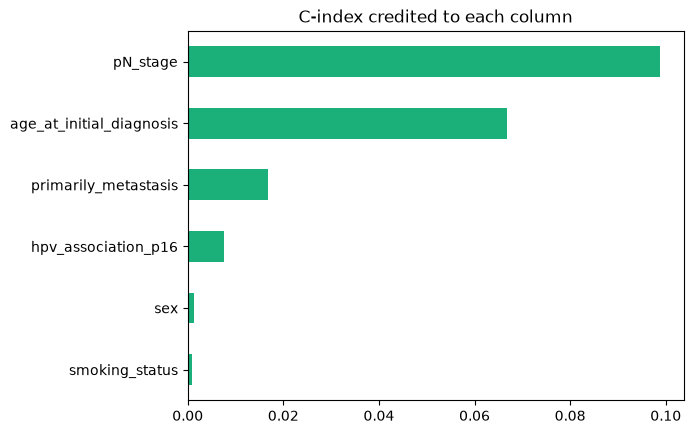

In [10]:
from kalecancer.interpret import feature_shapley

credit = feature_shapley(pathology_model['pipeline'], pathology_model['test'], HarrellC(), modality='clinical', n_samples=30)
credit.sort_values().plot.barh(title='C-index credited to each column', color='#1baf7a');

<details><summary>Hints</summary>

- Try `['pT_stage', 'pN_stage']`, then add `'lymphovascular_invasion_L'`, `'perineural_invasion_Pn'` or `'resection_status'`.
- `hpv_association_p16` is `not_tested` for most non-oropharynx patients. The model treats that as its own category: is "not tested" informative?
- 🔴 Stages are text, so they are numbered alphabetically. Turn them into numbers yourself, e.g. `pathology_table['pN_stage'].str.extract(r'(\d)')[0].astype(float)`, and see whether it helps.
- Pathology is recorded after surgery. That's fine for predicting outcome after surgery, but not for a model meant to be used at diagnosis.
</details>

---
## Question 4 🟡 Do blood tests add anything?

Blood tests become a third modality (one more entry in `modalities`).

**Your task:** run it, then try without the slides (remove `'slides': slides`), or only a few tests such as `blood_table[['leukocytes', 'hemoglobin', 'platelets']]`.

In [11]:
print('Available:', ', '.join(blood_table.columns))

blood_model = experiment('Clinical + blood + slides', {'clinical': clinical, 'blood': blood_table, 'slides': slides})  # ✏️
compare(blood_model, baseline)

Available: basophils, basophils_pct, calcium, creatinine, eosinophils, eosinophils_pct, erythrocytes, glomerular_filtration_rate, granulocytes, granulocytes_pct, hematocrit, hemoglobin, inr, immature_granulocytyes, leukocytes, lymphocytes, lymphocytes_pct, mch, mcv, mhch, mpv, monocytes, monocytes_pct, normoblasts, pdw, plcr, pt, platelets, potassium, rdw, sodium, thrombin_time, appt


Clinical + blood + slides (in split): C-index 0.647 (95% CI 0.55 to 0.74)


Gain: -0.015 (95% CI -0.09 to +0.05): no clear difference


Leave-one-out ablation removes one modality at a time.

Shapley averages over every combination.


In [12]:
from kalecancer.interpret import leave_one_out_ablation, modality_shapley

pd.DataFrame({
    'Shapley value': modality_shapley(blood_model['pipeline'], blood_model['test'], HarrellC()),
    'C-index lost when removed': leave_one_out_ablation(blood_model['pipeline'], blood_model['test'], HarrellC())
}).round(3)

,Shapley value,C-index lost when removed
clinical,0.019,0.008
blood,0.041,0.051
slides,-0.033,-0.033


<details><summary>Hints</summary>

- Inflammation markers such as the neutrophil-to-lymphocyte ratio are reported as prognostic in head and neck cancer. 🔴 Add one: `blood_table.assign(nlr=blood_table['granulocytes'] / blood_table['lymphocytes'])`.
- Try the blood tests in the clinical table instead of as a separate modality: `{'clinical': clinical.join(blood_table)}`. Which works better here?
</details>

---
## Question 5 🟡 What about a different outcome?

Changing the outcome changes only the target. The data, model and pipeline stay the same.

### 5a Recurrence instead of death

For recurrence-free survival, the event is recurrence, and patients without one are followed until their last visit.

In [13]:
recurred = clinical_table['recurrence'] == 'yes'
recurrence_free = TimeToEvent(
    time=clinical_table['days_to_recurrence'].where(recurred, clinical_table['days_to_last_information']),
    event=recurred
)

recurrence_clinical = experiment('Recurrence: clinical', {'clinical': clinical}, target=recurrence_free)
recurrence_fused = experiment('Recurrence: clinical + slides', {'clinical': clinical, 'slides': slides}, target=recurrence_free)
compare(recurrence_fused, recurrence_clinical)

Recurrence: clinical (in split): C-index 0.624 (95% CI 0.54 to 0.73)


Recurrence: clinical + slides (in split): C-index 0.588 (95% CI 0.48 to 0.69)


Gain: -0.036 (95% CI -0.17 to +0.07): no clear difference


### 5b Can the slide alone tell HPV status?

HPV-driven tumours look different under the microscope. If the slide features can predict p16 status, the model has learned real biology, and a routine H&E slide could flag patients for testing.

For classification, swap the target (`Classification`), the head (`ClassificationHead`) and the metric (`AUROC`). `clone(pipeline).set_params(...)` reuses everything else from section 1. Only the 312 tested patients with a slide are used.

In [14]:
from sklearn.base import clone
from kalecancer.loaddata import Classification
from kalecancer.model import Unimodal, ClassificationHead
from kalecancer.evaluate import AUROC, EvalContext, bootstrap_ci

tested = pathology_table.index[pathology_table['hpv_association_p16'] != 'not_tested']
hpv_data = MultimodalDataset(
    modalities={'slides': slides},
    target=Classification(labels=pathology_table.loc[tested, 'hpv_association_p16'], classes=['negative', 'positive']),
    required_modalities=['slides']
)
hpv_train, hpv_test = official_split(hpv_data, 'in')

torch.manual_seed(0)
slide_model = Unimodal('slides', [ABMIL(in_dim=1024, hidden_dim=64, attention_dim=32, dropout=0.25)], ClassificationHead(in_dim=64, n_classes=2))
hpv_pipeline = clone(pipeline).set_params(model=slide_model, transforms={}).fit(hpv_train)

predictions = hpv_pipeline.predict(hpv_test)
auroc = bootstrap_ci(AUROC(positive_class='positive'), predictions, hpv_test.target.frame.loc[predictions.index],
                     EvalContext(train_target=hpv_pipeline.train_target_, classes=['negative', 'positive']))
print(f'HPV status from the slide: AUROC {auroc.estimate:.2f} (95% CI {auroc.lower:.2f} to {auroc.upper:.2f}), {len(predictions)} test patients')

HPV status from the slide: AUROC 0.81 (95% CI 0.70 to 0.91), 74 test patients


<details><summary>Hints</summary>

- An AUROC of 0.5 is chance. Is the lower end of the interval above it?
- HPV-positive tumours are almost all in the oropharynx, so tumour site alone predicts much of it. 🔴 Is the slide learning HPV, or just tumour site? Restrict to oropharynx patients: `tested = tested[pathology_table.loc[tested, 'primary_tumor_site'] == 'Oropharynx']`.
- 🔴 `attention(hpv_pipeline, hpv_test, 'slides')` from `kalecancer.interpret` gives the weight of every patch, to see where the model looks.
</details>

---
## Question 6 🔴 Going further

**Is the slide gain real?** The official test set has only about 40 deaths. `cross_validate` refits everything in every fold and uses every patient as a test patient once. This takes about a minute.

In [15]:
from sklearn.model_selection import StratifiedKFold
from kalecancer.evaluate import cross_validate

torch.manual_seed(0)
clinical_model = Unimodal('clinical', [MLP(in_dim=4, hidden_dims=[64], out_dim=64, dropout=0.25)], CoxHead(in_dim=64, ties='efron'))
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

for name, candidate in {'Clinical': clinical_model, 'Clinical + slides': model}.items():  # ✏️ add your own model
    scores = cross_validate(clone(pipeline).set_params(model=candidate), dataset, folds, {'harrell_c': HarrellC()}).folds['harrell_c']
    print(f'{name}: C-index {scores.mean():.3f} ± {scores.std():.3f} over 5 folds')

Clinical: C-index 0.620 ± 0.061 over 5 folds


Clinical + slides: C-index 0.630 ± 0.026 over 5 folds


**More ideas**

- **Your own slide encoder.** Any `torch.nn.Module` whose `forward` takes a list of bags (one `(patches, 1024)` tensor per patient) and returns one vector per patient can replace `ABMIL`. Does attention beat a plain average of the patches?
- **Late fusion:** `LateFusion` from `kalecancer.model`, as in the walkthrough.
- **Other metrics:** `UnoC`, `TimeDependentAUC`, `IntegratedBrier` and `CalibrationError` from `kalecancer.evaluate`. Is the best-ranking model also the best calibrated?
- **Share your best model:** `dump_config(pipeline)` from `kalecancer.pipeline` writes it to YAML, and `load_pipeline` rebuilds it anywhere.

---
## Results

Every `experiment` you ran, best first.

,experiment,split,test patients,C-index,lower,upper
0,"Clinical + pN_stage, hpv_association_p16",in,152,0.709,0.603,0.789
1,Clinical + slides,in,152,0.662,0.581,0.737
2,Clinical,in,152,0.651,0.567,0.734
3,Clinical + blood + slides,in,152,0.647,0.548,0.739
4,Recurrence: clinical,in,152,0.624,0.540,0.729
5,Clinical + slides,Oropharynx,331,0.614,0.548,0.681
6,Recurrence: clinical + slides,in,152,0.588,0.479,0.690
7,Clinical,Oropharynx,331,0.583,0.516,0.645


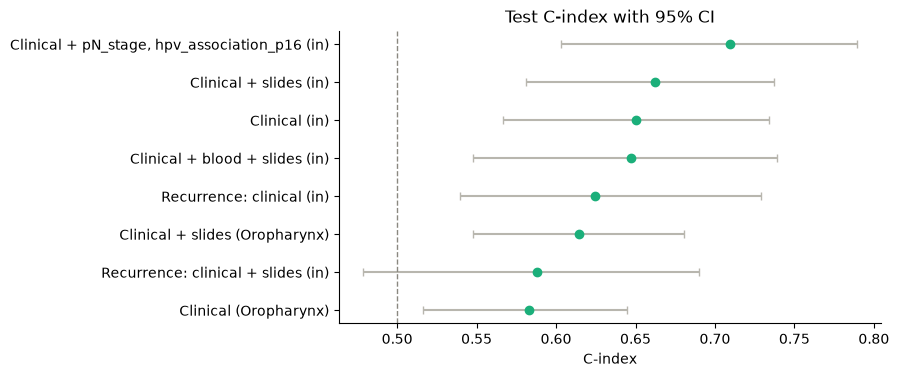

In [16]:
from hancock_data import plot_results

plot_results()